In [1]:
from pathlib import Path  # handles folder paths same as linux and windows
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# importing paths
Raw = Path(".../data/raw")  # ... is one folder up from notebooks/

Out = Path(".../data/processed")  # ... is one folder up from notebooks/
# out shows where the cleaned data will be saved
# creates the folder if it doesn't exist, and doesn't raise an error if it does
Out.mkdir(parents=True, exist_ok=True)

FIG = Path(".../figures")
FIG.mkdir(parents=True, exist_ok=True)
# loading the sensor matrix

Raw = Path.cwd().parent / "data" / "raw"

# The notebook is in /home/eli/Dev/secom-spc
project_root = Path("/home/eli/Dev/secom-spc")
Raw = project_root / "data" / "raw"

data_file = Raw / "secom.data"

if not data_file.exists():
    raise FileNotFoundError(f"Dataset not found: {data_file}")

X = pd.read_csv(data_file, sep=r"\s+", header=None)

X.columns = [f"s{i:03d}" for i in range(X.shape[1])]

print(X.shape)
print(X.iloc[:3, :5])
# printing the first 3 runs, 5 sensors

(1567, 590)
      s000     s001       s002       s003    s004
0  3030.93  2564.00  2187.7333  1411.1265  1.3602
1  3095.78  2465.14  2230.4222  1463.6606  0.8294
2  2932.61  2559.94  2186.4111  1698.0172  1.5102


In [2]:
#labels and timestamps
lab = pd.read_csv(Raw / "secom_labels.data", sep=r"\s+", header=None,
                  names=["label", "timestamp"])
# each row: -1 (pass) or 1 (fail), then the run's date/time in quotes (pandas strips the quotes)
lab["timestamp"] = pd.to_datetime(lab["timestamp"], format="%d/%m/%Y %H:%M:%S")
# text -> real datetime; the file is day/month/year, so the format must say so
lab["fail"] = (lab["label"] == 1).astype(int)
# 1 = failed the line test, 0 = passed; a 0/1 column averages straight to a fail rate
print(lab.head(3))
print(lab["label"].value_counts())
# how many passes and fails

   label           timestamp  fail
0     -1 2008-07-19 11:55:00     0
1     -1 2008-07-19 12:32:00     0
2      1 2008-07-19 13:17:00     1
label
-1    1463
 1     104
Name: count, dtype: int64


Join and sort by time

In [3]:
#join labels and sensors, sort by time

df = pd.concat([lab[["timestamp", "fail"]], X], axis=1) #puts labels and sensors side by side, row i of each file corresponds to the same time point
print("already in time order:", df["timestamp"].is_monotonic_increasing)
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True).copy()
# sort anyway, so the code stays correct even if the file weren't sorted
# kind="stable" keeps file order for runs with the same timestamp
# reset_index: row number = position in time
# .copy() packs the table into one memory block (avoids a pandas warning later)
print(df["timestamp"].min(), "->", df["timestamp"].max())
print("duplicate timestamps:", df["timestamp"].duplicated().sum())
# runs logged at the exact same minute

already in time order: True
2008-07-19 11:55:00 -> 2008-10-17 06:07:00
duplicate timestamps: 33


failt rate and drift over time

fail rate: 0.0664  fails: 104 of 1567
            count  sum      rate
timestamp                       
2008-07-20     13    3  0.230769
2008-07-27     21    2  0.095238
2008-08-03     48   10  0.208333
2008-08-10    108   14  0.129630
2008-08-17     51    7  0.137255
2008-08-24    208   22  0.105769
2008-08-31    169    7  0.041420
2008-09-07    133    2  0.015038
2008-09-14     95    4  0.042105
2008-09-21    154    5  0.032468
2008-09-28    166    4  0.024096
2008-10-05    169   15  0.088757
2008-10-12    138    8  0.057971
2008-10-19     94    1  0.010638


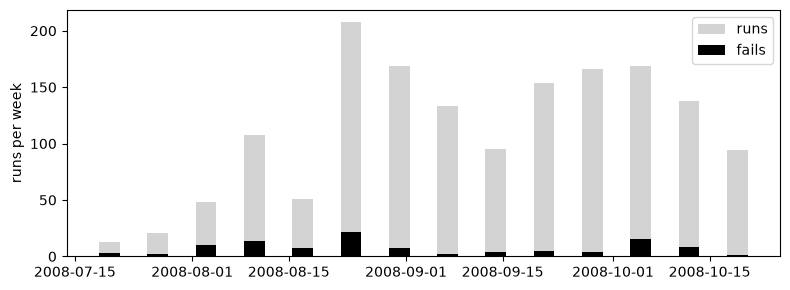

In [4]:
print("fail rate:", round(df["fail"].mean(), 4), " fails:", df["fail"].sum(), "of", len(df))
# the mean of a 0/1 column is the fraction of fails
weekly = df.set_index("timestamp")["fail"].resample("W").agg(["count", "sum"])
# group runs into calendar weeks: count = runs that week, sum = fails that week
weekly["rate"] = weekly["sum"] / weekly["count"]
# weekly fail fraction
print(weekly)

fig, ax = plt.subplots(figsize=(8, 3))
# one plot, 8 x 3 
ax.bar(weekly.index, weekly["count"], width=3, color="lightgray", label="runs")
# gray bar = all runs that week (width is in days)
ax.bar(weekly.index, weekly["sum"], width=3, color="black", label="fails")
# black bar drawn on top = the fails
ax.set_ylabel("runs per week")
ax.legend()
fig.tight_layout()
# trims empty margins
fig.savefig(FIG / "weekly_fails.png", dpi=150)
# saved for the report
plt.show()

Missing values?

In [5]:
sensors = df.columns[2:]
# every column after timestamp and fail
miss = df[sensors].isna().mean()
# isna() gives True/False per cell; the mean of True/False is the fraction missing, per sensor
print("cells missing:", round(df[sensors].isna().values.mean(), 4))
# over the whole table
print("sensors with any missing:", (miss > 0).sum())
print("sensors > 50% missing:", (miss > 0.5).sum())
print(miss.sort_values(ascending=False).head(8).round(3))
# the 8 worst sensors

cells missing: 0.0454
sensors with any missing: 538
sensors > 50% missing: 28
s292    0.912
s293    0.912
s158    0.912
s157    0.912
s492    0.856
s085    0.856
s358    0.856
s220    0.856
dtype: float64


Sensors that never change

In [6]:
std = df[sensors].std()
# standard deviation per sensor (missing values skipped)
constant = std[std == 0].index
# zero spread = the sensor reads the same value every run, so it carries no information
print("constant sensors:", len(constant))
print("all-NaN sensors:", df[sensors].isna().all().sum())

constant sensors: 116
all-NaN sensors: 0


train/test split by time

In [7]:
n_train = int(0.7 * len(df))
# first 70% of runs in time = training, last 30% = test
cut = df["timestamp"].iloc[n_train]
# the first test run's time
train = df.iloc[:n_train]
# iloc slices by row position; rows are in time order, so this is "everything before the cut"
test = df.iloc[n_train:]
print("cut at", cut)
print("train:", len(train), "runs, fail rate", round(train["fail"].mean(), 4))
print("test: ", len(test), "runs, fail rate", round(test["fail"].mean(), 4))

cut at 2008-09-26 03:12:00
train: 1096 runs, fail rate 0.0712
test:  471 runs, fail rate 0.0552


Save tidy table

In [8]:
df = df.assign(split=np.where(df.index < n_train, "train", "test"))
# add a "split" column; np.where(condition, if True, if False)
# assign() returns a new table with the extra column
df.to_csv(Out / "secom_tidy.csv", index=False)
# index=False: don't write the row numbers as an extra column
print(pd.read_csv(Out / "secom_tidy.csv").shape)
# read back to check: 590 sensors + timestamp + fail + split

(1567, 593)


Findings:

- There is a sever class imbalance, the SECOM dataset contains 1,567 total production runs across 590 unamed sensor channels. There were only 104 observed failures, resulting in an overall base failure rate of 6.64%.
- Resampling failure coutns by claendar week sows that the manufacturing line is non-stationary ove rthe 3 month window from July 19 to October 17, 2008. Weekly defect rates fluctuated between 10% and 23% during July and August, but dropped sharply at the end of august down to 1.5% to 4.2% across September and October. This indicates an operational or process shift. 